# Colorado streamflow (USGS)

Companion to the `snow_pack` and `co_groundwater` notebooks. Uses the **USGS Water Data OGC API** (`api.waterdata.usgs.gov`), not the legacy `waterservices` endpoints that are being decommissioned in early 2027.

- Parameter `00060` = discharge, **cubic feet per second (cfs)**. Statistic `00003` = daily mean.
- Focus gauge defaults to the **Yampa River at Steamboat Springs** (the Glas Deffryn Ranch basin); change `FOCUS_NAME` or set `FOCUS_SITE` to use another gauge.
- Section 4 compares the current water year to the historical distribution, which is the core drought signal. Section 5 writes a dashboard snapshot of every Colorado gauge reporting now.
- Put `USGS_API_KEY=...` in a `.env` file next to the notebook (optional, but avoids 429s).

In [1]:
import os
import json
import time
import hashlib
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import date, timedelta
from pathlib import Path

def load_env(name=".env"):
    """Find .env in the working dir or any parent, load KEY=VALUE lines into os.environ."""
    for d in [Path.cwd(), *Path.cwd().parents]:
        f = d / name
        if f.is_file():
            for line in f.read_text(encoding="utf-8-sig").splitlines():
                line = line.strip()
                if not line or line.startswith("#") or "=" not in line:
                    continue
                k, v = line.split("=", 1)
                if not os.environ.get(k.strip()):
                    os.environ[k.strip()] = v.strip().strip('"').strip("'")
            return f
    return None

print(".env:", load_env() or "NOT FOUND (looked in cwd and its parents)", "| cwd:", Path.cwd())

.env: C:\Users\lilli\work\classes\gpgn438-design-drought-analysis\inital_data_exploration\.env | cwd: C:\Users\lilli\work\classes\gpgn438-design-drought-analysis\inital_data_exploration


In [2]:
BASE_URL = "https://api.waterdata.usgs.gov/ogcapi/v0"
API_KEY = os.environ.get("USGS_API_KEY") or None
Q_PARAM = "00060"                         # discharge, cfs
CFS_DAY_TO_ACRE_FT = 1.9835               # 1 cfs for one day = 1.9835 acre-feet
CO_BBOX = (-109.06, 36.99, -102.04, 41.00)  # lon_min, lat_min, lon_max, lat_max

MIN_INTERVAL = 0.5 if API_KEY else 1.5    # seconds between requests
CACHE_DIR = Path(".cache"); CACHE_DIR.mkdir(exist_ok=True)
_last_call = [0.0]

def _get_json(url, query, headers, retries=8, use_cache=True, ttl_hours=6):
    """GET with throttling, backoff on 429/5xx (honors Retry-After), disk cache, readable 4xx errors."""
    key = hashlib.md5(f"{url}|{sorted((query or {}).items())}".encode()).hexdigest()
    cache_file = CACHE_DIR / f"{key}.json"
    if use_cache and cache_file.exists() and time.time() - cache_file.stat().st_mtime < ttl_hours * 3600:
        return json.loads(cache_file.read_text())
    for attempt in range(retries):
        wait = MIN_INTERVAL - (time.time() - _last_call[0])
        if wait > 0:
            time.sleep(wait)
        resp = requests.get(url, params=query, headers={"X-Api-Key": API_KEY} if API_KEY else {}, timeout=60)
        _last_call[0] = time.time()
        if resp.status_code in (429, 500, 502, 503, 504):
            delay = float(resp.headers.get("Retry-After", min(2 ** attempt * 2, 120)))
            print(f"  HTTP {resp.status_code}; sleeping {delay:.0f}s (attempt {attempt + 1}/{retries})")
            time.sleep(delay)
            continue
        if resp.status_code >= 400:
            raise requests.HTTPError(f"{resp.status_code} for {resp.url}\n{resp.text[:600]}", response=resp)
        js = resp.json()
        if use_cache:
            cache_file.write_text(json.dumps(js))
        return js
    resp.raise_for_status()

def ogc_get(collection, max_pages=100, **params):
    """GET /collections/{collection}/items, follow pagination, return a DataFrame
    (feature properties as columns, point geometry as longitude/latitude)."""
    clean = {}
    for k, v in params.items():
        if v is None:
            continue
        if isinstance(v, bool):
            v = str(v).lower()
        elif isinstance(v, (list, tuple)):
            v = ",".join(map(str, v))
        clean[k] = v
    clean.setdefault("f", "json")
    clean.setdefault("limit", 10000)
    url, query, rows, pages = f"{BASE_URL}/collections/{collection}/items", clean, [], 0
    while url and pages < max_pages:
        js = _get_json(url, query, {})
        for feat in js.get("features", []):
            row = dict(feat.get("properties") or {})
            row["feature_id"] = feat.get("id")
            geom = feat.get("geometry") or {}
            if geom.get("type") == "Point":
                row["longitude"], row["latitude"] = geom["coordinates"][:2]
            rows.append(row)
        url = next((l["href"] for l in js.get("links", []) if l.get("rel") == "next"), None)
        query = None   # the "next" link already carries the full query string
        pages += 1
    return pd.DataFrame(rows)

print("Ready. API key set:", bool(API_KEY))

Ready. API key set: True


## 1. Colorado stream gauges and the focus site

In [3]:
co_streams = ogc_get("monitoring-locations", state_name="Colorado", site_type_code="ST")
if "monitoring_location_id" not in co_streams.columns:
    co_streams["monitoring_location_id"] = co_streams["feature_id"]
co_streams = co_streams.drop_duplicates("monitoring_location_id").reset_index(drop=True)
print(f"{len(co_streams)} Colorado stream monitoring locations")

FOCUS_SITE = None                          # e.g. "USGS-09239500" to override the name search
FOCUS_NAME = "yampa river at steamboat"    # case-insensitive substring of the site name

names = co_streams.get("monitoring_location_name", pd.Series("", index=co_streams.index)).fillna("")
site_names = dict(zip(co_streams["monitoring_location_id"], names))

if FOCUS_SITE is None:
    cand = co_streams[names.str.contains(FOCUS_NAME, case=False, regex=False)]
    if cand.empty:
        cand = co_streams[names.str.contains("yampa", case=False, regex=False)]
    if cand.empty:
        raise RuntimeError("No Yampa gauges found; set FOCUS_SITE to a monitoring_location_id.")
    print("Candidates:"); print(cand[["monitoring_location_id", "monitoring_location_name"]].head(10).to_string(index=False))
    FOCUS_SITE = cand.iloc[0]["monitoring_location_id"]
print("Focus site:", FOCUS_SITE, "-", site_names.get(FOCUS_SITE, ""))

6128 Colorado stream monitoring locations
Candidates:
monitoring_location_id             monitoring_location_name
         USGS-09239500 YAMPA RIVER AT STEAMBOAT SPRINGS, CO
Focus site: USGS-09239500 - YAMPA RIVER AT STEAMBOAT SPRINGS, CO


## 2. Daily mean discharge for the focus site

`daily` returns one value per day. Dates are local calendar days.

In [4]:
def get_daily_flow(site_id, begin="1990-10-01", end=None):
    """Daily mean discharge (cfs) as a DataFrame with a tz-naive `date` column."""
    end = end or date.today().isoformat()
    df = ogc_get("daily", monitoring_location_id=site_id, parameter_code=Q_PARAM,
                 time=f"{begin}/{end}", skipGeometry=True)
    if df.empty:
        return df
    if "statistic_id" in df.columns:
        mean = df[df["statistic_id"] == "00003"]
        df = mean if not mean.empty else df
    df["value"] = pd.to_numeric(df["value"], errors="coerce")
    df["date"] = pd.to_datetime(df["time"], utc=True).dt.tz_localize(None).dt.normalize()
    return df.dropna(subset=["value"]).sort_values("date").reset_index(drop=True)

hist = get_daily_flow(FOCUS_SITE)
if hist.empty:
    raise RuntimeError(f"No daily discharge for {FOCUS_SITE}. Try another gauge via FOCUS_SITE.")
print(f"{len(hist)} daily values, {hist['date'].min().date()} to {hist['date'].max().date()}")
hist[["monitoring_location_id", "date", "value"]].tail()

13167 daily values, 1990-10-01 to 2026-10-18


,monitoring_location_id,date,value
13162,USGS-09239500,2026-10-14,120.0
13163,USGS-09239500,2026-10-15,137.0
13164,USGS-09239500,2026-10-16,122.0
13165,USGS-09239500,2026-10-17,122.0
13166,USGS-09239500,2026-10-18,118.0


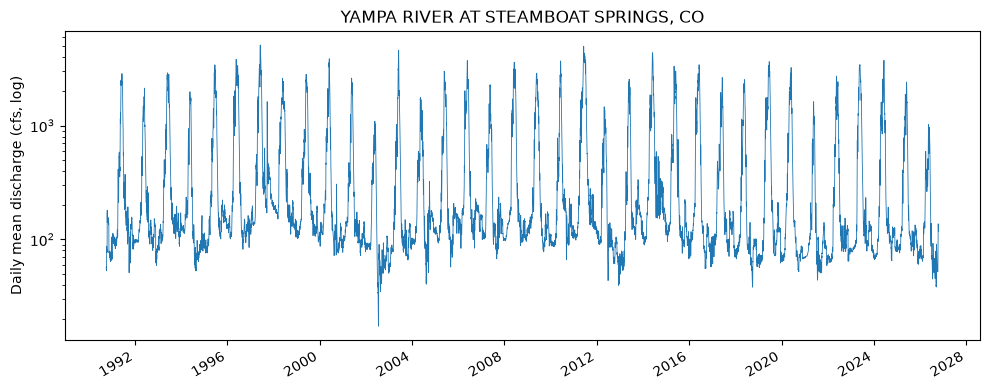

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(hist["date"], hist["value"], lw=0.6)
ax.set_yscale("log")
ax.set_ylabel("Daily mean discharge (cfs, log)")
ax.set_title(f"{site_names.get(FOCUS_SITE, FOCUS_SITE)}")
fig.autofmt_xdate(); plt.tight_layout(); plt.show()

## 3. Water-year statistics

Water year (WY) runs Oct 1 to Sep 30 and is named for the year it ends in. Years with fewer than 350 daily values are treated as incomplete and excluded from the drought ranking.

In [6]:
h = hist.copy()
h["wy"] = h["date"].dt.year + (h["date"].dt.month >= 10).astype(int)
h["wy_day"] = (h["date"] - pd.to_datetime((h["wy"] - 1).astype(str) + "-10-01")).dt.days

ann = (h.groupby("wy")
         .agg(days=("value", "size"), mean_cfs=("value", "mean"), peak_cfs=("value", "max"),
              total_cfs_days=("value", "sum"))
         .assign(volume_acre_ft=lambda d: d["total_cfs_days"] * CFS_DAY_TO_ACRE_FT))
ann["min_7day_cfs"] = h.groupby("wy")["value"].apply(lambda s: s.rolling(7).mean().min())
ann["complete"] = ann["days"] >= 350

full = ann[ann["complete"]]
q25 = full["volume_acre_ft"].quantile(0.25)
ann["dry_year"] = ann["complete"] & (ann["volume_acre_ft"] <= q25)
print(f"{len(full)} complete water years; dry-year threshold (25th pct volume): {q25:,.0f} acre-ft")
ann.round(1).tail(10)

36 complete water years; dry-year threshold (25th pct volume): 241,527 acre-ft


,days,mean_cfs,peak_cfs,total_cfs_days,volume_acre_ft,min_7day_cfs,complete,dry_year
wy,,,,,,,,
2018,365,343.8,2530.0,125502.8,248934.8,40.9,True,False
2019,365,531.4,3640.0,193977.8,384755.0,55.0,True,False
2020,366,422.5,3230.0,154616.9,306682.6,53.7,True,False
2021,365,186.8,1620.0,68189.0,135252.9,46.7,True,True
2022,365,345.2,2720.0,126012.0,249944.8,61.5,True,False
2023,365,498.1,3420.0,181805.2,360610.6,73.3,True,False
2024,366,468.5,3740.0,171482.8,340136.1,68.0,True,False
2025,365,318.2,2410.0,116127.7,230339.3,67.1,True,True
2026,365,181.6,1020.0,66283.0,131472.3,40.4,True,True


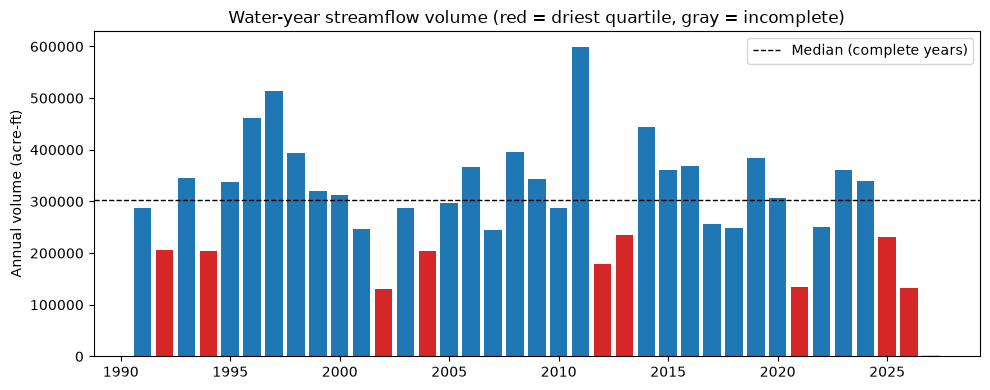

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
colors = np.where(ann["dry_year"], "tab:red", np.where(ann["complete"], "tab:blue", "lightgray"))
ax.bar(ann.index, ann["volume_acre_ft"], color=colors)
ax.axhline(full["volume_acre_ft"].median(), color="k", lw=1, ls="--", label="Median (complete years)")
ax.set_ylabel("Annual volume (acre-ft)")
ax.set_title("Water-year streamflow volume (red = driest quartile, gray = incomplete)")
ax.legend(); plt.tight_layout(); plt.show()

## 4. Current water year vs. the historical distribution

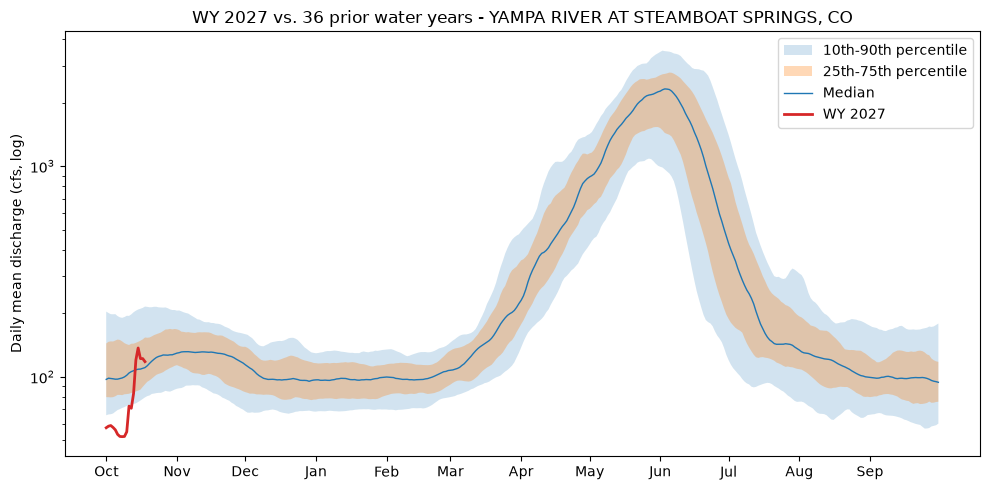

Latest (2026-10-18): 118 cfs = 55th percentile for this time of year
WY 2027 volume to date: 2,773 acre-ft vs median 3,725 (74% of median)


In [8]:
cur_wy = int(h["wy"].max())
base = h[(h["wy"] < cur_wy)]
cur = h[h["wy"] == cur_wy]

qs = [0.10, 0.25, 0.50, 0.75, 0.90]
clim = base.groupby("wy_day")["value"].quantile(qs).unstack()
clim = clim.rolling(7, center=True, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(10, 5))
ax.fill_between(clim.index, clim[0.10], clim[0.90], alpha=0.2, label="10th-90th percentile")
ax.fill_between(clim.index, clim[0.25], clim[0.75], alpha=0.3, label="25th-75th percentile")
ax.plot(clim.index, clim[0.50], lw=1, label="Median")
ax.plot(cur["wy_day"], cur["value"], lw=2, color="tab:red", label=f"WY {cur_wy}")
ax.set_yscale("log")
month_starts = [0, 31, 61, 92, 123, 151, 182, 212, 243, 273, 304, 335]
ax.set_xticks(month_starts)
ax.set_xticklabels(["Oct", "Nov", "Dec", "Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep"])
ax.set_ylabel("Daily mean discharge (cfs, log)")
ax.set_title(f"WY {cur_wy} vs. {base['wy'].nunique()} prior water years - {site_names.get(FOCUS_SITE, FOCUS_SITE)}")
ax.legend(); plt.tight_layout(); plt.show()

# where does the latest day sit relative to the same time of year historically?
last = cur.iloc[-1]
window = base[(base["wy_day"] - last["wy_day"]).abs() <= 3]["value"]
pct = float((window < last["value"]).mean() * 100)

# volume so far this water year vs. the median for the same point in prior years
cum_cur = cur["value"].sum() * CFS_DAY_TO_ACRE_FT
cum_prior = (base[base["wy_day"] <= last["wy_day"]].groupby("wy")["value"].sum() * CFS_DAY_TO_ACRE_FT)
cum_med = float(cum_prior.median())
print(f"Latest ({last['date'].date()}): {last['value']:,.0f} cfs = {pct:.0f}th percentile for this time of year")
print(f"WY {cur_wy} volume to date: {cum_cur:,.0f} acre-ft vs median {cum_med:,.0f} ({cum_cur / cum_med * 100:.0f}% of median)")

## 5. Dashboard snapshot: every Colorado gauge reporting now

Asks `latest-continuous` for discharge inside Colorado's bounding box, so only live gauges come back, in a few requests. The box also catches slivers of neighboring states along the border; filter on the Colorado site list below if that matters. This is the piece a scheduled GitHub Action should run.

In [9]:
def find_active_gauges(max_age_days=3):
    frames = []
    for coll in ("latest-continuous", "latest-daily"):
        try:
            f = ogc_get(coll, parameter_code=Q_PARAM, bbox=CO_BBOX)
        except requests.HTTPError as err:
            print(f"  {coll}: {err}")
            continue
        print(f"  {coll}: {len(f)} rows")
        if f.empty:
            continue
        f["time"] = pd.to_datetime(f["time"], utc=True)
        f["value"] = pd.to_numeric(f["value"], errors="coerce")
        f["source"] = coll
        frames.append(f[["monitoring_location_id", "time", "value", "source"]])
    if not frames:
        return pd.DataFrame(columns=["monitoring_location_id", "latest_time", "latest_cfs", "source"])
    df = (pd.concat(frames, ignore_index=True)
            .rename(columns={"time": "latest_time", "value": "latest_cfs"})
            .dropna(subset=["latest_cfs"])
            .sort_values("latest_time", ascending=False)
            .drop_duplicates("monitoring_location_id"))
    return df[df["latest_time"] >= pd.Timestamp.now(tz="UTC") - pd.Timedelta(days=max_age_days)]

gauges = find_active_gauges()
gauges["name"] = gauges["monitoring_location_id"].map(site_names)
gauges["in_colorado_list"] = gauges["monitoring_location_id"].isin(co_streams["monitoring_location_id"])
gauges["is_focus"] = gauges["monitoring_location_id"] == FOCUS_SITE
gauges["generated_utc"] = pd.Timestamp.now(tz="UTC").isoformat(timespec="seconds")
print(f"{len(gauges)} gauges reporting in the last 3 days ({gauges['in_colorado_list'].sum()} on the Colorado list)")
gauges.sort_values("latest_cfs", ascending=False).head(10)

  latest-continuous: 618 rows
  latest-daily: 1282 rows
289 gauges reporting in the last 3 days (279 on the Colorado list)


,monitoring_location_id,latest_time,latest_cfs,source,name,in_colorado_list,is_focus,generated_utc
469,USGS-09163500,2026-10-19 14:45:00+00:00,2710.0,latest-continuous,COLORADO RIVER NEAR COLORADO-UTAH STATE LINE,True,False,2026-10-19T15:15:34+00:00
410,USGS-09371010,2026-10-19 14:00:00+00:00,1610.0,latest-continuous,"SAN JUAN RIVER AT FOUR CORNERS, CO",True,False,2026-10-19T15:15:34+00:00
437,USGS-09095500,2026-10-19 14:45:00+00:00,1460.0,latest-continuous,"COLORADO RIVER NEAR CAMEO, CO.",True,False,2026-10-19T15:15:34+00:00
174,USGS-09363500,2026-10-19 14:00:00+00:00,1390.0,latest-continuous,"ANIMAS RIVER NEAR CEDAR HILL, NM",True,False,2026-10-19T15:15:34+00:00
163,USGS-09362520,2026-10-19 15:00:00+00:00,1290.0,latest-continuous,ANIMAS RIVER BLW DURANGO PUMP PLANT NR DURANGO...,True,False,2026-10-19T15:15:34+00:00
9,USGS-09152500,2026-10-19 14:30:00+00:00,1240.0,latest-continuous,"GUNNISON RIVER NEAR GRAND JUNCTION, CO.",True,False,2026-10-19T15:15:34+00:00
125,USGS-09361500,2026-10-19 14:30:00+00:00,1230.0,latest-continuous,"ANIMAS RIVER AT DURANGO, CO",True,False,2026-10-19T15:15:34+00:00
164,USGS-09085100,2026-10-19 14:15:00+00:00,1230.0,latest-continuous,"COLORADO RIVER BELOW GLENWOOD SPRINGS, CO",True,False,2026-10-19T15:15:34+00:00
487,USGS-09359500,2026-10-19 14:00:00+00:00,859.0,latest-continuous,ANIMAS RIVER AT TALL TIMBER RESORT ABOVE TACOM...,True,False,2026-10-19T15:15:34+00:00
552,USGS-09349800,2026-10-19 14:15:00+00:00,688.0,latest-continuous,"PIEDRA RIVER NEAR ARBOLES, CO.",True,False,2026-10-19T15:15:34+00:00


In [10]:
out_dir = Path("data"); out_dir.mkdir(exist_ok=True)
gauges.to_csv(out_dir / "co_streamflow_latest.csv", index=False)
gauges.to_json(out_dir / "co_streamflow_latest.json", orient="records", date_format="iso", indent=2)

focus = {
    "site": FOCUS_SITE, "name": site_names.get(FOCUS_SITE, ""), "water_year": cur_wy,
    "latest_date": str(last["date"].date()), "latest_cfs": round(float(last["value"]), 1),
    "percentile_for_date": round(pct, 1),
    "wy_volume_to_date_acre_ft": round(float(cum_cur)), "median_volume_to_date_acre_ft": round(cum_med),
    "pct_of_median_volume": round(float(cum_cur / cum_med * 100), 1),
    "generated_utc": pd.Timestamp.now(tz="UTC").isoformat(timespec="seconds"),
}
(out_dir / "co_streamflow_focus.json").write_text(json.dumps(focus, indent=2))
ann.reset_index().assign(site=FOCUS_SITE).to_csv(out_dir / "co_streamflow_annual.csv", index=False)  # read by the ENSO notebook
print("Wrote", out_dir / "co_streamflow_latest.csv", ",", out_dir / "co_streamflow_latest.json", ",", out_dir / "co_streamflow_focus.json")

Wrote data\co_streamflow_latest.csv , data\co_streamflow_latest.json , data\co_streamflow_focus.json
